# 01 – Data Ingestion und Raw Layer

Dieses Notebook macht den Einstieg in die Pipeline sichtbar: Welche Yahoo-Finance-Snapshots liegen vor, welchen Zeitraum decken sie ab und wie unterscheiden sich die Kursverläufe? Die Rohdaten werden hier ausschließlich gelesen und nicht verändert.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import RAW_PRICE_DIR, TICKERS
from src.preprocessing import find_latest_raw_file, load_profile

pd.set_option('display.max_columns', 20)
plt.style.use('seaborn-v0_8-whitegrid')

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\sheo1\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


## Snapshot-Inventar

Für jeden Ticker wird automatisch der neueste timestamp-basierte Raw-Snapshot gewählt. Das ist derselbe Datenvertrag, den das Preprocessing verwendet.

In [2]:
raw_frames = []
inventory = []

for ticker in TICKERS:
    path = find_latest_raw_file(RAW_PRICE_DIR, ticker, 'csv')
    frame = pd.read_csv(path)
    date_column = 'Date' if 'Date' in frame.columns else 'Datetime'
    frame['trade_date'] = pd.to_datetime(frame[date_column].astype(str).str[:10])
    frame['ticker'] = ticker
    raw_frames.append(frame)
    inventory.append({
        'ticker': ticker,
        'snapshot': path.name,
        'rows': len(frame),
        'first_date': frame['trade_date'].min().date(),
        'last_date': frame['trade_date'].max().date(),
        'missing_close': int(frame['Close'].isna().sum()),
    })

raw_prices = pd.concat(raw_frames, ignore_index=True)
inventory_df = pd.DataFrame(inventory)
inventory_df

,ticker,snapshot,rows,first_date,last_date,missing_close
0,AAPL,AAPL_20260825T213028Z.csv,1254,2021-08-26,2026-08-25,0
1,MSFT,MSFT_20260825T213028Z.csv,1254,2021-08-26,2026-08-25,0
2,NVDA,NVDA_20260825T213028Z.csv,1254,2021-08-26,2026-08-25,0
3,SAP.DE,SAP_DE_20260825T213028Z.csv,1275,2021-08-25,2026-08-25,0
4,ALV.DE,ALV_DE_20260825T213028Z.csv,1275,2021-08-25,2026-08-25,0


## Vergleichbare Kursentwicklung

Da die Aktien unterschiedliche absolute Preise haben, werden alle Reihen am ersten verfügbaren Tag auf 100 normiert. So ist die relative Entwicklung direkt vergleichbar.

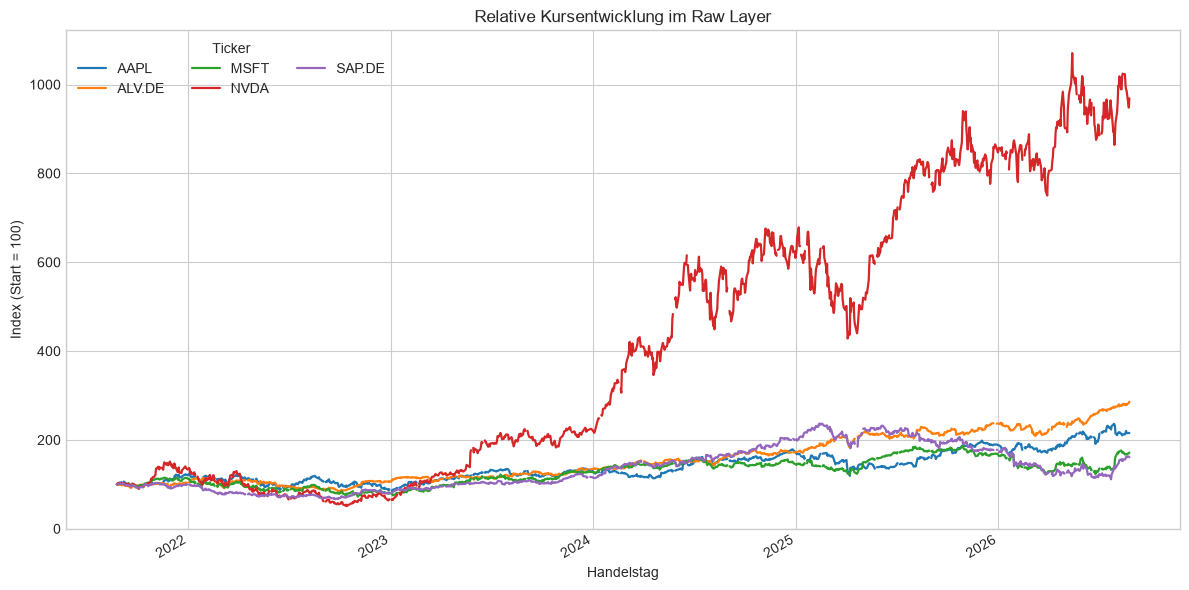

In [3]:
close_prices = raw_prices.pivot_table(index='trade_date', columns='ticker', values='Close')
normalized = close_prices.divide(close_prices.apply(lambda series: series.dropna().iloc[0])) * 100

ax = normalized.plot(figsize=(12, 6), linewidth=1.6)
ax.set(title='Relative Kursentwicklung im Raw Layer', xlabel='Handelstag', ylabel='Index (Start = 100)')
ax.legend(title='Ticker', ncol=3)
plt.tight_layout()
plt.show()

## Unternehmensstammdaten

Neben den Zeitreihen enthält der Raw Layer Profile, aus denen die Dimensionstabelle `dim_stock` aufgebaut wird.

In [4]:
profile_rows = []
for ticker in TICKERS:
    profile = load_profile(ticker)
    profile_rows.append({
        'ticker': ticker,
        'company': profile.get('longName') or profile.get('shortName'),
        'sector': profile.get('sector'),
        'country': profile.get('country'),
        'currency': profile.get('currency'),
        'exchange': profile.get('exchange'),
    })
pd.DataFrame(profile_rows)

,ticker,company,sector,country,currency,exchange
0,AAPL,Apple Inc.,Technology,United States,USD,NMS
1,MSFT,Microsoft Corporation,Technology,United States,USD,NMS
2,NVDA,NVIDIA Corporation,Technology,United States,USD,NMS
3,SAP.DE,SAP SE,Technology,Germany,EUR,GER
4,ALV.DE,Allianz SE,Financial Services,Germany,EUR,GER


## Ergebnis

Der Raw Layer enthält für alle fünf PoC-Aktien historische Tagesdaten und Stammdaten. Die timestamp-basierten Dateien bleiben unverändert erhalten und ermöglichen eine reproduzierbare Weiterverarbeitung.